# Student Academic Performance Prediction using Deep Neural Networks

Course project for 24CAI0306 Deep Neural Networks (B.E. CSE-AIML, Semester 5).

**Task.** Predict whether a student will **pass** the year (final grade G3 ≥ 10 out of 20) or is **at risk** of failing (G3 < 10).
The prediction uses 32 demographic, academic, social and behavioural attributes, including the two period grades G1 and G2.

**Data.** UCI Student Performance, Portuguese course: 649 students from two Portuguese secondary schools.

**Model.** A PyTorch multilayer perceptron with BatchNorm, dropout, He initialisation, AdamW and early stopping, tuned with Optuna.
It is compared with a majority-class baseline, a one-line rule, logistic regression, random forest and XGBoost under the same cross-validation.

All code lives in `src/`, and every section below calls it, so the notebook and the scripts can never disagree.
A full run takes about 2 minutes on a laptop CPU (about 8 on Kaggle).

| # | Section | | # | Section |
|---|---|---|---|---|
| 1 | Setup | | 10 | Final evaluation on the locked test set |
| 2 | The dataset: all 33 columns | | 11 | What the model relies on |
| 3 | Exploratory data analysis | | 12 | Predicting individual students |
| 4 | Target and locked test split | | 13 | Under the hood: the network in NumPy |
| 5 | Feature audit and selection | | 14 | The same network in Keras |
| 6 | Preprocessing pipeline | | 15 | Training experiments from the course practicals |
| 7 | The DNN: architecture and training loop | | 16 | Hardware: CPU vs GPU |
| 8 | Hyperparameter tuning (Optuna) | | 17 | Supplementary: no grades, and results history |
| 9 | Cross-validated comparison with traditional ML | | 18 | Conclusions and limitations |

## 1. Setup

In [1]:
import os, sys, subprocess

os.environ.setdefault("OMP_NUM_THREADS", "1")   # set before torch/xgboost load: avoids a libomp crash on macOS; 1 thread is fastest on data this small
os.environ.setdefault("KERAS_BACKEND", "torch")  # Keras 3 runs on PyTorch here, so TensorFlow isn't needed

if not os.path.exists("src"):  # on Kaggle: fetch the project code and data from GitHub
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/auraCodesKM/student-performance-dnn.git"], check=True)
    os.chdir("student-performance-dnn")
sys.path.insert(0, os.getcwd())

import inspect, json, time, warnings
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
from IPython.display import Image, Markdown, display
from sklearn.metrics import accuracy_score, f1_score, precision_recall_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline

from src import evaluate, experiments, tune
from src.data import CATEGORICAL, DESCRIPTIONS, FEATURES, GRADES, GROUPS, NUMERIC, SEED, load_data, make_preprocessor, split
from src.eda import audit, feature_audit, figures, vif
from src.model import MLP, DNNClassifier
from src.numpy_mlp import NumpyMLP, gradient_check
%matplotlib inline
pd.set_option("display.max_colwidth", 60)
GREEN, GREY, ORANGE = "#16a34a", "#a1a1aa", "#ea580c"

print("python", sys.version.split()[0], "| torch", torch.__version__, "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

python 3.12.2 | torch 2.15.0 | scikit-learn 1.9.1 | pandas 3.1.1


## 2. The dataset: all 33 columns

The CSV has 33 columns: 30 attributes, the two period grades G1 and G2, and the final grade G3.
G3 becomes the target, so the model gets **32 inputs**. Each is listed below with its group (as in the brief), its type and its encoding.

In [2]:
df = load_data()
group_of = {c: g for g, cols in GROUPS.items() for c in cols}
columns = pd.DataFrame({
    "column": list(df.columns[:33]),
    "description": [DESCRIPTIONS.get(c, "Final grade (0-20): the target") for c in df.columns[:33]],
    "group": [group_of.get(c, "Target") for c in df.columns[:33]],
    "type": ["target" if c == "G3" else "grade" if c in GRADES else "numeric / ordinal" if c in NUMERIC else "categorical" for c in df.columns[:33]],
    "distinct values": [df[c].nunique() for c in df.columns[:33]],
    "role": ["target (never an input)" if c == "G3" else "input" for c in df.columns[:33]],
})
print(f"{df.shape[0]} students × 33 columns; {len(FEATURES)} inputs ({len(NUMERIC) + len(GRADES)} numeric incl. G1/G2, {len(CATEGORICAL)} categorical)")
columns

649 students × 33 columns; 32 inputs (15 numeric incl. G1/G2, 17 categorical)


,column,description,group,type,distinct values,role
0,school,School (GP or MS),Academic,categorical,2,input
1,sex,Sex,Demographic,categorical,2,input
2,age,Age (15-22),Demographic,numeric / ordinal,8,input
3,address,Home address (urban / rural),Demographic,categorical,2,input
4,famsize,Family size (<=3 / >3),Demographic,categorical,2,input
5,Pstatus,Parents together / apart,Demographic,categorical,2,input
6,Medu,Mother's education (0-4),Demographic,numeric / ordinal,5,input
7,Fedu,Father's education (0-4),Demographic,numeric / ordinal,5,input
8,Mjob,Mother's job,Demographic,categorical,5,input
9,Fjob,Father's job,Demographic,categorical,5,input


## 3. Exploratory data analysis

Each check below led to a pipeline decision (all of them are listed in `DECISIONS.md`):
- **No missing values and no duplicates**, so no imputation is needed.
- **Only 15.4% of students are at risk.** Predicting "pass" for everyone already scores 84.6%, so accuracy alone is misleading. Macro-F1 is used for tuning, and recall is reported alongside it.
- **All 15 students with G3 = 0 also have 0 absences.** They most likely dropped out or missed the final exam. They are real fails and are kept.
- **G2 alone predicts G3 well**, so the rule "at risk if G2 < 10" is a baseline the DNN has to beat.
- **Absences are right-skewed but within the codebook range**, so no outliers are removed.

In [3]:
audit(df)

Shape: (649, 34)
Missing values: 0
Duplicate rows: 0
At-risk (G3 < 10) share: 15.4% -> majority-class accuracy would be 84.6%
G3 == 0: 15 students; with zero absences: 15 (vs 37.6% of all students) -> likely dropped out / missed the final exam
Correlation with G3: {'G1': 0.826, 'G2': 0.919}
'Pass if G2 >= 10' rule accuracy: 89.7%
Absences skew: 2.02 max: 32


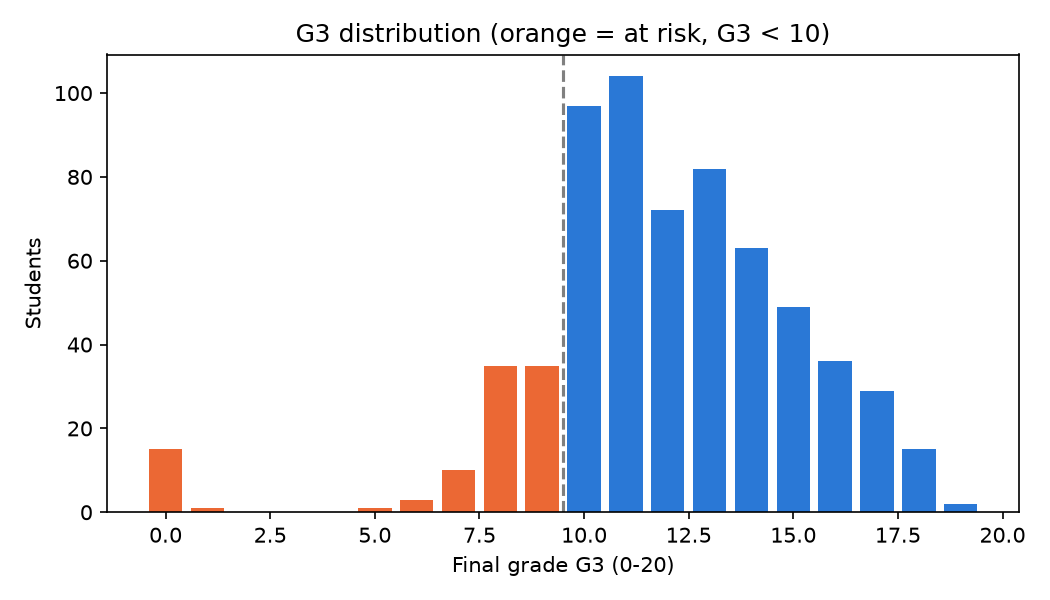

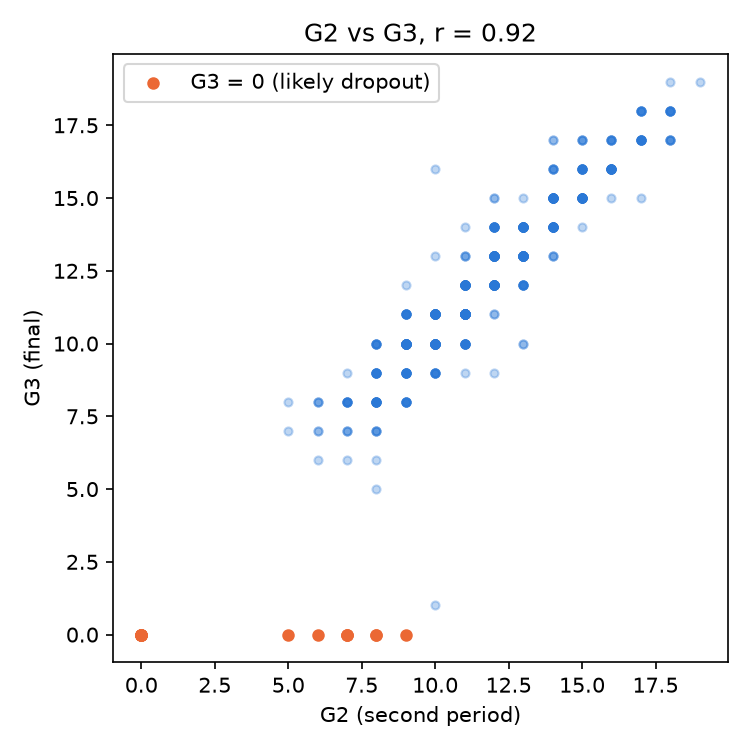

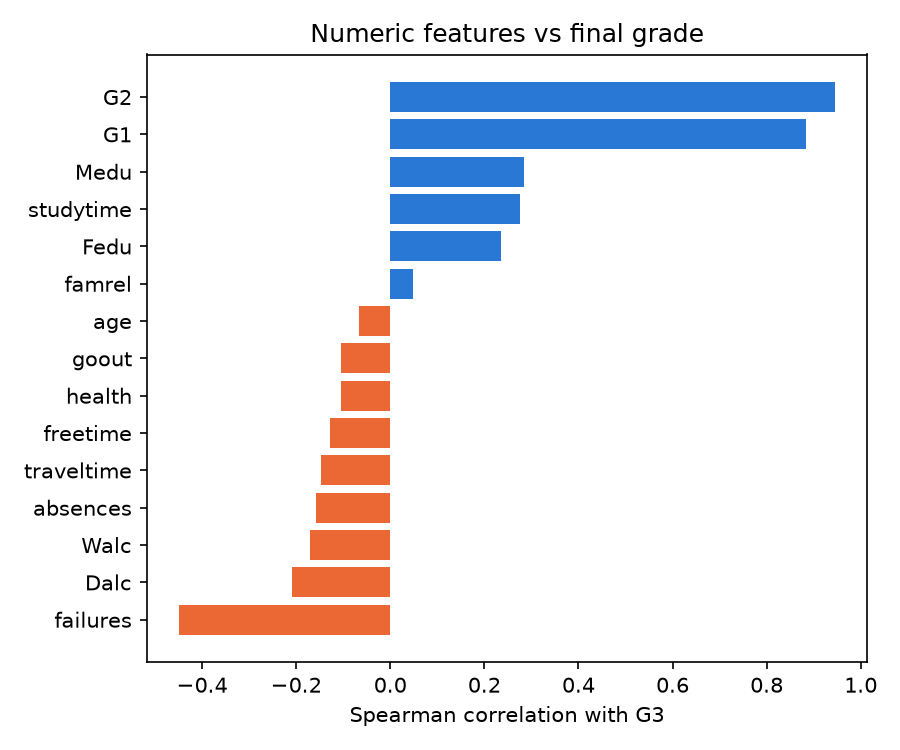

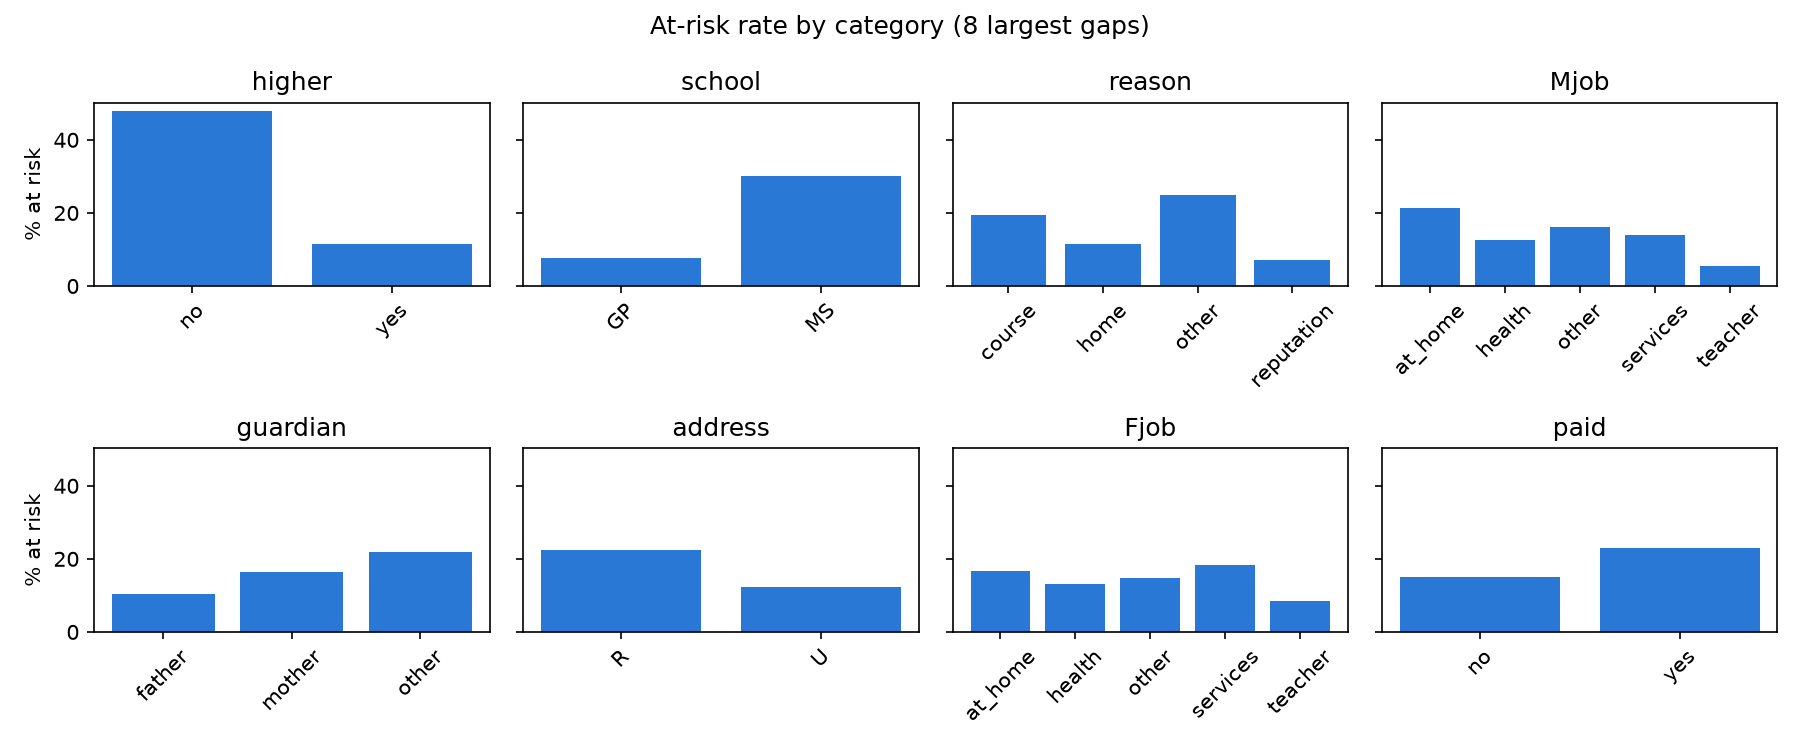

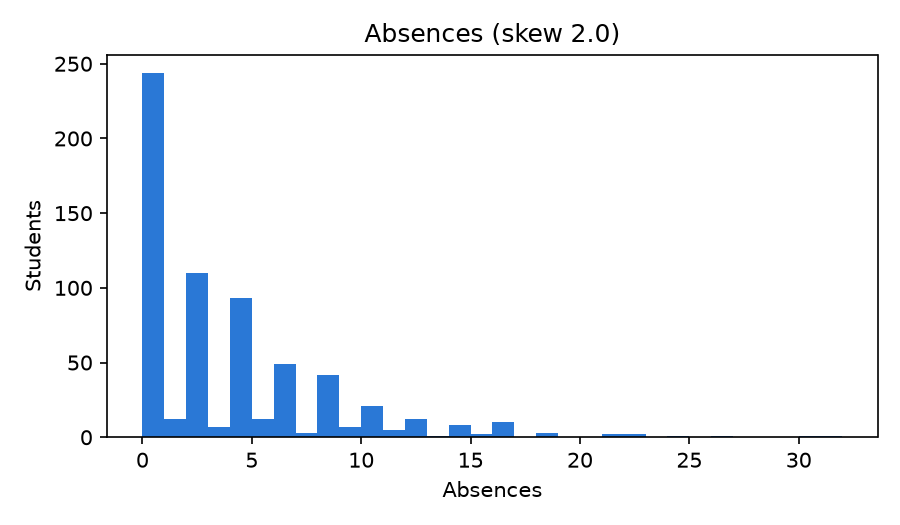

In [4]:
figures(df)  # saves the EDA plots to results/figures/
for name in ["g3_distribution", "g2_vs_g3", "correlations", "risk_by_category", "absences"]:
    display(Image(f"results/figures/{name}.png", width=680))

## 4. Target and locked test split

Target: `at_risk = 1 if G3 < 10 else 0`. At risk is the positive class, because those are the students a school wants to find.

The data is split 80/20 with stratification, so both parts keep the 15.4% at-risk share.
The 130 test students are **locked**: they are used once, in section 10, after all tuning and model choices are made.

In [5]:
train, test = split(df)
print(f"train: {len(train)} students, {train.at_risk.sum()} at risk ({train.at_risk.mean():.1%})")
print(f"test:  {len(test)} students, {test.at_risk.sum()} at risk ({test.at_risk.mean():.1%})  <- locked until section 10")

train: 519 students, 80 at risk (15.4%)
test:  130 students, 20 at risk (15.4%)  <- locked until section 10


## 5. Feature audit and selection

**Every one of the 32 inputs is a candidate. None was removed by hand.** The only exclusion is G3, because it is the target.

Feature selection is automatic and happens inside the pipeline: `SelectKBest` keeps the k encoded columns with the highest **mutual information** with `at_risk`.
Mutual information measures how much knowing a column reduces uncertainty about the outcome, and it captures non-linear links that correlation misses.
Every input is an integer code, a 0/1 flag or a whole-number grade, so mutual information is computed from counts (`discrete_features=True`).

The table below is computed on the **training students only**. `kept_in_folds` shows how often a column survives selection across the same 15 cross-validation folds used in section 9, which tells you how stable the choice is.

In [6]:
audit_table = feature_audit(train)
audit_table.drop(columns="description").round(3)

,feature,group,type,encoding,spearman_with_G3,at_risk_rate_gap,kept_in_folds,in_final_model
15,school,Academic,categorical,one 0/1 column,NaN,0.232,15/15,True
2,Fedu,Demographic,numeric/ordinal,standardised,0.248,NaN,15/15,True
4,studytime,Academic,numeric/ordinal,standardised,0.270,NaN,15/15,True
5,failures,Academic,numeric/ordinal,standardised,-0.467,NaN,15/15,True
29,higher,Academic,categorical,one 0/1 column,NaN,0.348,15/15,True
12,absences,Behavioural,numeric/ordinal,standardised,-0.138,NaN,15/15,True
13,G1,Academic,grade,standardised,0.885,NaN,15/15,True
14,G2,Academic,grade,standardised,0.943,NaN,15/15,True
1,Medu,Demographic,numeric/ordinal,standardised,0.268,NaN,10/15,True
6,famrel,Social,numeric/ordinal,standardised,0.078,NaN,9/15,True


**Reading the audit.**
- **Kept in all 15 folds:** G1, G2, failures, higher, school, studytime, Fedu and absences. These are the stable signals.
- **Medu and famrel** fill the last two slots in most folds. They are weak signals close to the cut-off.
- **Lost to the grades:** alcohol use, going out, health and family size have weak links with G3 (|ρ| ≤ 0.2).
- **Not discarded by hand:** each input simply loses the competition for the 10 slots, and every fold re-runs that competition.

**Multicollinearity.** The variance inflation factor (VIF) is 1 / (1 − R²) when a column is regressed on the other numeric columns.
G1 and G2 are strongly correlated (r = 0.86), but their VIF is about 4, below the common warning level of 5. Everything else is below 2.
For a neural network, correlated inputs are not an error; they mainly make individual weights hard to interpret.

**How many features?** Optuna tried k = 10, 15, 20 and all 45 columns. k = 10 scored best on average and was chosen in 29 of the 40 trials.
Fewer, stronger inputs help a small network trained on 519 students.

In [7]:
display(vif(train).round(2).to_frame("VIF").T)

# Optuna tuned k (how many encoded columns to keep). Mean CV macro-F1 of all trials for each k:
trials = pd.read_csv("results/experiments.csv")
display(trials.groupby("k").cv_f1_macro.agg(["count", "mean", "max"]).round(3).rename(columns={"count": "trials"}))

,G1,G2,Walc,Medu,Fedu,Dalc,failures,goout,freetime,age,studytime,traveltime,absences,famrel,health
VIF,4.05,4.03,1.82,1.81,1.77,1.73,1.37,1.36,1.21,1.21,1.14,1.11,1.1,1.1,1.07


,trials,mean,max
k,,,
10,29,0.833,0.870
15,2,0.809,0.817
20,6,0.809,0.818
all,3,0.791,0.809


## 6. Preprocessing pipeline

Three steps that learn from data:
1. **One-hot encoding** for the 17 categorical columns. Yes/no columns become a single 0/1 column, so no fake order is invented.
2. **Standardisation** ((x − mean) / std) for the 15 numeric columns, so every input has a similar scale for gradient descent.
3. **SelectKBest** with mutual information.

All three are steps of one scikit-learn `Pipeline` together with the model. Whenever the pipeline is fitted, whether on a CV training fold or on the full training set, these steps are fitted on those rows only.
No mean, standard deviation or mutual-information score from a validation or test student can leak into training.

In [8]:
params = json.load(open("results/best_params.json"))
pipe = tune.build_dnn(params)
display(pipe)

pre = Pipeline(pipe.steps[:-1]).fit(train, train.at_risk)
encoded = pre.named_steps["encode"].transform(train)
print(f"32 inputs -> {encoded.shape[1]} columns after one-hot encoding -> {params['k']} kept:",
      ", ".join(pre.named_steps["select"].get_feature_names_out()))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('encode', ...), ('select', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name

32 inputs -> 45 columns after one-hot encoding -> 10 kept: school_MS, higher_yes, Medu, Fedu, studytime, failures, famrel, absences, G1, G2


## 7. The DNN: architecture and training loop

The network chosen by Optuna has **10 inputs → 16 → 8 → 1 output**. Each hidden layer is `Linear → BatchNorm → ReLU → Dropout(0.48)`.
- **He initialisation** suits ReLU: weights are drawn with variance 2 / fan_in, so activations neither shrink nor explode layer by layer.
- The single output is a **logit** z. P(at risk) = sigmoid(z) = 1 / (1 + e^(−z)).
- `BCEWithLogitsLoss` computes the binary cross-entropy −[y·log p + (1 − y)·log(1 − p)] directly from the logit, which is numerically stable.
- The final model is a **seed ensemble**: 5 networks trained from different random starts, with their probabilities averaged.

In [9]:
hidden = tuple(max(8, params["width"] // 2**i) for i in range(params["n_layers"]))
net = MLP(n_inputs=params["k"], hidden=hidden, dropout=round(params["dropout"], 2), batchnorm=params["batchnorm"])
print(net)
rows = [(name, tuple(p.shape), p.numel()) for name, p in net.named_parameters()]
display(pd.DataFrame(rows, columns=["parameter", "shape", "count"]))
n_params = sum(p.numel() for p in net.parameters())
print("trainable parameters per network:", n_params, "| ensemble of 5:", 5 * n_params)

MLP(
  (net): Sequential(
    (0): Linear(in_features=10, out_features=16, bias=True)
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.48, inplace=False)
    (4): Linear(in_features=16, out_features=8, bias=True)
    (5): BatchNorm1d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.48, inplace=False)
    (8): Linear(in_features=8, out_features=1, bias=True)
  )
)


,parameter,shape,count
0,net.0.weight,"(16, 10)",160
1,net.0.bias,"(16,)",16
2,net.1.weight,"(16,)",16
3,net.1.bias,"(16,)",16
4,net.4.weight,"(8, 16)",128
5,net.4.bias,"(8,)",8
6,net.5.weight,"(8,)",8
7,net.5.bias,"(8,)",8
8,net.8.weight,"(1, 8)",8
9,net.8.bias,"(1,)",1


trainable parameters per network: 369 | ensemble of 5: 1845


The training loop below runs **zero_grad → forward pass → loss → backward (backpropagation) → optimizer step**, one shuffled mini-batch at a time.

`model.train()` turns dropout on and makes BatchNorm use batch statistics. `model.eval()` turns dropout off and makes BatchNorm use its running averages.

Early stopping holds out 15% of the *training* rows, never the test set. When validation loss has not improved for 30 epochs, training stops and the weights from the best epoch are restored.

In [10]:
print(inspect.getsource(DNNClassifier._train_one))

    def _train_one(self, X, y, seed):
        torch.manual_seed(seed)
        # Hold out 15% of the training rows to decide when to stop (never the test set).
        X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.15, stratify=y, random_state=seed)
        X_tr, y_tr, X_val, y_val = map(torch.from_numpy, (X_tr, y_tr, X_val, y_val))

        model = MLP(X.shape[1], self.hidden, self.dropout, self.batchnorm)
        # AdamW = Adam with decoupled weight decay (L2-style regularisation).
        optimizer = torch.optim.AdamW(model.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        # Only ~15% of students fail. pos_weight = (#pass / #fail) makes each missed failure cost as much
        # as all the passes it is outnumbered by, so the model can't ignore the minority class.
        pos_weight = (len(y_tr) - y_tr.sum()) / y_tr.sum() if self.class_weight else torch.tensor(1.0)
        loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)  # sigmoid + binary cross-en

## 8. Hyperparameter tuning (Optuna)

Optuna's TPE sampler searched 9 hyperparameters: depth, width, dropout, BatchNorm, learning rate, weight decay, batch size, class weights and the number of features k.
- It ran 40 trials. Each trial was scored by **mean macro-F1 over 5-fold × 2-repeat cross-validation on the training set only**.
- The 10 folds make each score less dependent on one lucky split.
- Every trial is logged in `results/experiments.csv`.

Re-running the search takes about 10 minutes, so by default this section loads the saved log. Set `RUN_TUNING = True` to run it again.

In [11]:
print(inspect.getsource(tune.objective).split('    # 5-fold')[0])  # the search space

def objective(trial, train):
    params = {
        "n_layers": trial.suggest_int("n_layers", 1, 3),
        "width": trial.suggest_categorical("width", [16, 32, 64, 128]),
        "dropout": trial.suggest_float("dropout", 0.0, 0.5),
        "batchnorm": trial.suggest_categorical("batchnorm", [True, False]),
        "lr": trial.suggest_float("lr", 1e-4, 1e-2, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-5, 1e-2, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [16, 32, 64]),
        "class_weight": trial.suggest_categorical("class_weight", [True, False]),
        "k": trial.suggest_categorical("k", [10, 15, 20, "all"]),
    }



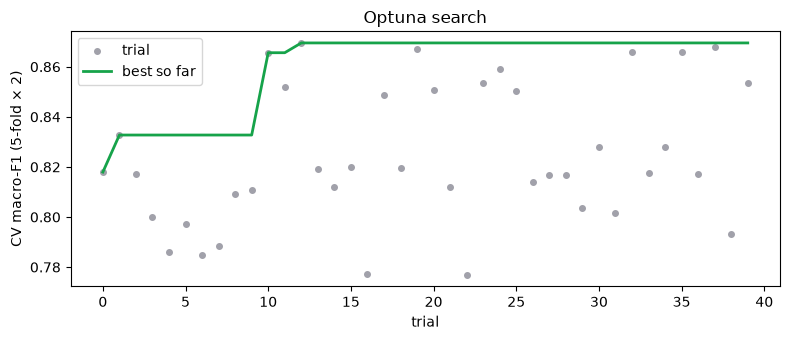

,trial,n_layers,width,dropout,batchnorm,lr,weight_decay,batch_size,class_weight,k,cv_f1_macro,cv_f1_std
12,12,2,16,0.4786,True,0.0020,0.0084,32,False,10,0.8695,0.0638
37,37,2,16,0.4859,True,0.0016,0.0008,64,False,10,0.8677,0.0679
19,19,2,16,0.4871,True,0.0026,0.0004,32,False,10,0.8671,0.0703
35,35,2,16,0.4494,True,0.0025,0.0001,32,False,10,0.8661,0.0647
32,32,2,16,0.4622,True,0.0014,0.0004,64,False,10,0.8659,0.0651


{'n_layers': 2,
 'width': 16,
 'dropout': 0.47863507341115996,
 'batchnorm': True,
 'lr': 0.001996353900698521,
 'weight_decay': 0.00843330780209246,
 'batch_size': 32,
 'class_weight': False,
 'k': 10}

In [12]:
RUN_TUNING = False  # True re-runs all 40 trials and overwrites results/best_params.json
if RUN_TUNING:
    tune.main()
    trials, params = pd.read_csv("results/experiments.csv"), json.load(open("results/best_params.json"))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.scatter(trials.trial, trials.cv_f1_macro, s=16, color=GREY, label="trial")
ax.plot(trials.trial, trials.cv_f1_macro.cummax(), color=GREEN, lw=2, label="best so far")
ax.set(xlabel="trial", ylabel="CV macro-F1 (5-fold × 2)", title="Optuna search"); ax.legend(); plt.tight_layout(); plt.show()

cols = ["trial", "n_layers", "width", "dropout", "batchnorm", "lr", "weight_decay", "batch_size", "class_weight", "k", "cv_f1_macro", "cv_f1_std"]
display(trials.sort_values("cv_f1_macro", ascending=False).head(5)[cols].round(4))
params

## 9. Cross-validated comparison with traditional ML

`evaluate.main()` runs the full comparison:
1. **Baselines.** Grid-searches logistic regression, random forest and XGBoost with the same preprocessing, CV and metric, so the fight is fair. It also adds a majority-class baseline and the "G2 < 10" rule.
2. **Cross-validation.** Scores every model with **5-fold × 3-repeat CV** on the 519 training students. It uses a different random seed from tuning, so the scores are not the tuning scores reused.
3. **Test set.** Refits each model on all 519 training students and scores the **130 locked test students once**.
4. **DNN stability.** Retrains the DNN with 5 different seeds and adds Wilson and bootstrap 95% intervals plus McNemar tests.
5. **Outputs.** Saves `models/dnn.joblib` (used by the app), the figures and `results/RESULTS.md`.

In [13]:
evaluate.main()

  Logistic regression: {'model__C': 10, 'model__class_weight': None, 'select__k': 20}


  Random forest: {'model__class_weight': 'balanced_subsample', 'model__max_depth': 6, 'model__min_samples_leaf': 5}


  XGBoost: {'model__max_depth': 3, 'model__n_estimators': 400, 'model__scale_pos_weight': 5.5}
  Majority class         CV macro-F1 0.458 | test acc 0.846


  Naive rule (G2 < 10)   CV macro-F1 0.831 | test acc 0.900
  Logistic regression    CV macro-F1 0.870 | test acc 0.900


  Random forest          CV macro-F1 0.867 | test acc 0.862


  XGBoost                CV macro-F1 0.866 | test acc 0.900


  DNN (MLP)              CV macro-F1 0.846 | test acc 0.915



Wrote results/RESULTS.md, results/metrics.json and models/dnn.joblib


In [14]:
metrics = json.load(open("results/metrics.json"))
table = pd.DataFrame(metrics["models"]).T
cv_cols = {"cv_accuracy": "accuracy", "cv_accuracy_std": "± std", "cv_balanced_acc": "balanced acc", "cv_precision_at_risk": "precision",
           "cv_recall_at_risk": "recall", "cv_f1_macro": "macro-F1", "cv_f1_macro_std": "± std ", "cv_roc_auc": "ROC-AUC"}
display(Markdown("**Cross-validation, 5-fold × 3 repeats on the 519 training students** (mean over 15 folds)"))
display(table[list(cv_cols)].rename(columns=cv_cols).astype(float).style.format("{:.3f}"))

**Cross-validation, 5-fold × 3 repeats on the 519 training students** (mean over 15 folds)

,accuracy,± std,balanced acc,precision,recall,macro-F1,± std,ROC-AUC
Majority class,0.846,0.001,0.500,0.000,0.000,0.458,0.000,0.500
Naive rule (G2 < 10),0.896,0.031,0.893,0.617,0.887,0.831,0.046,0.963
Logistic regression,0.934,0.027,0.867,0.796,0.771,0.870,0.056,0.970
Random forest,0.921,0.029,0.916,0.691,0.908,0.867,0.045,0.974
XGBoost,0.929,0.023,0.878,0.757,0.804,0.866,0.045,0.971
DNN (MLP),0.925,0.027,0.821,0.823,0.671,0.846,0.051,0.971


**Reading the CV table.**
- With G1 and G2 available, every reasonable model reaches 92–93% CV accuracy and a CV ROC-AUC of about 0.97.
- The DNN is in that group: 92.5% accuracy, 0.971 ROC-AUC.
- Logistic regression has the best CV macro-F1, which is a sign that the decision boundary is close to linear in G2.
- The DNN's weakest number is **at-risk recall (0.67)**. Optuna chose no class weights, which favours precision over recall. Section 10 shows the threshold trade-off.

## 10. Final evaluation on the locked test set

These numbers come from the 130 students held out in section 4, each model scored once.

In [15]:
test_cols = {"test_accuracy": "accuracy", "test_balanced_acc": "balanced acc", "test_precision_at_risk": "precision",
             "test_recall_at_risk": "recall", "test_f1_at_risk": "F1 (at risk)", "test_f1_macro": "macro-F1", "test_roc_auc": "ROC-AUC"}
display(Markdown("**Locked test set, 130 students**"))
display(table[list(test_cols)].rename(columns=test_cols).astype(float).style.format("{:.3f}"))

d = metrics["dnn"]
print(d["classification_report"])
lo, hi = d["wilson_95ci_accuracy"]
print(f"DNN test accuracy {table.loc['DNN (MLP)', 'test_accuracy']:.3f}  (Wilson 95% CI {lo:.3f}–{hi:.3f}; "
      f"bootstrap {d['bootstrap_95ci']['accuracy'][0]:.3f}–{d['bootstrap_95ci']['accuracy'][1]:.3f})")
print(f"5 retrained copies: accuracy {d['seed_mean']['accuracy']:.3f} ± {d['seed_std']['accuracy']:.3f}, "
      f"macro-F1 {d['seed_mean']['f1_macro']:.3f} ± {d['seed_std']['f1_macro']:.3f}")
display(pd.DataFrame(d["seed_runs"], index=[f"seed {100 * s}" for s in range(5)]).round(3))

**Locked test set, 130 students**

,accuracy,balanced acc,precision,recall,F1 (at risk),macro-F1,ROC-AUC
Majority class,0.846,0.500,0.000,0.000,0.000,0.458,0.500
Naive rule (G2 < 10),0.900,0.900,0.621,0.900,0.735,0.837,0.953
Logistic regression,0.900,0.839,0.652,0.750,0.698,0.819,0.944
Random forest,0.862,0.857,0.531,0.850,0.654,0.784,0.946
XGBoost,0.900,0.859,0.640,0.800,0.711,0.825,0.925
DNN (MLP),0.915,0.848,0.714,0.750,0.732,0.841,0.953


              precision    recall  f1-score   support

        Pass      0.954     0.945     0.950       110
     At risk      0.714     0.750     0.732        20

    accuracy                          0.915       130
   macro avg      0.834     0.848     0.841       130
weighted avg      0.917     0.915     0.916       130

DNN test accuracy 0.915  (Wilson 95% CI 0.855–0.952; bootstrap 0.862–0.954)
5 retrained copies: accuracy 0.923 ± 0.008, macro-F1 0.850 ± 0.017


,accuracy,balanced_acc,precision_at_risk,recall_at_risk,f1_at_risk,f1_macro,roc_auc
seed 0,0.915,0.827,0.737,0.70,0.718,0.834,0.952
seed 100,0.931,0.857,0.789,0.75,0.769,0.864,0.957
seed 200,0.915,0.827,0.737,0.70,0.718,0.834,0.954
seed 300,0.923,0.832,0.778,0.70,0.737,0.846,0.953
seed 400,0.931,0.877,0.762,0.80,0.780,0.870,0.959


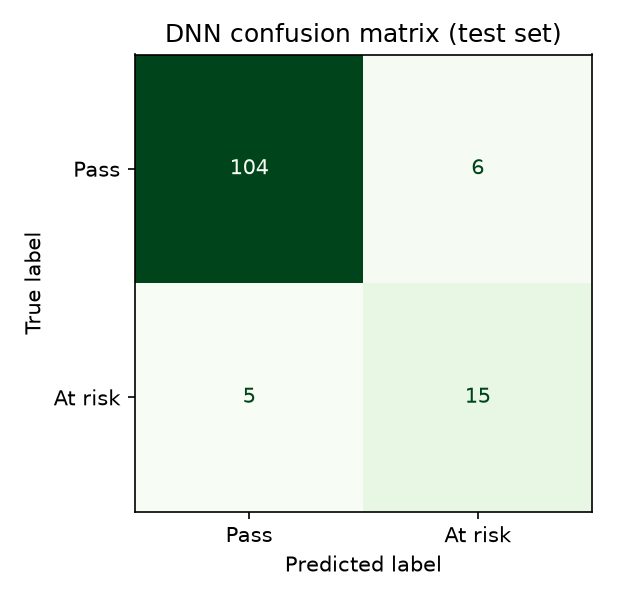

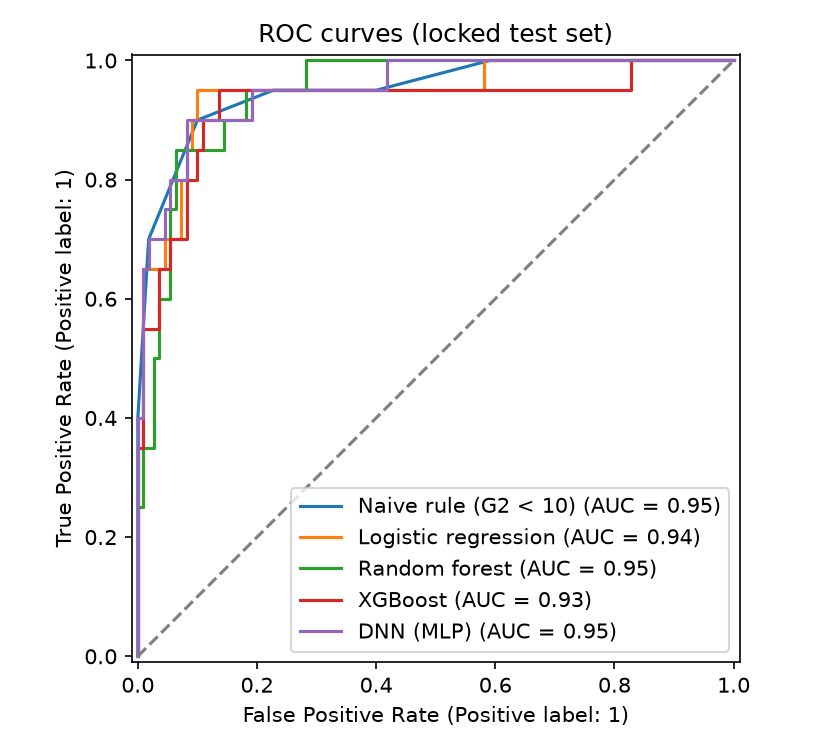

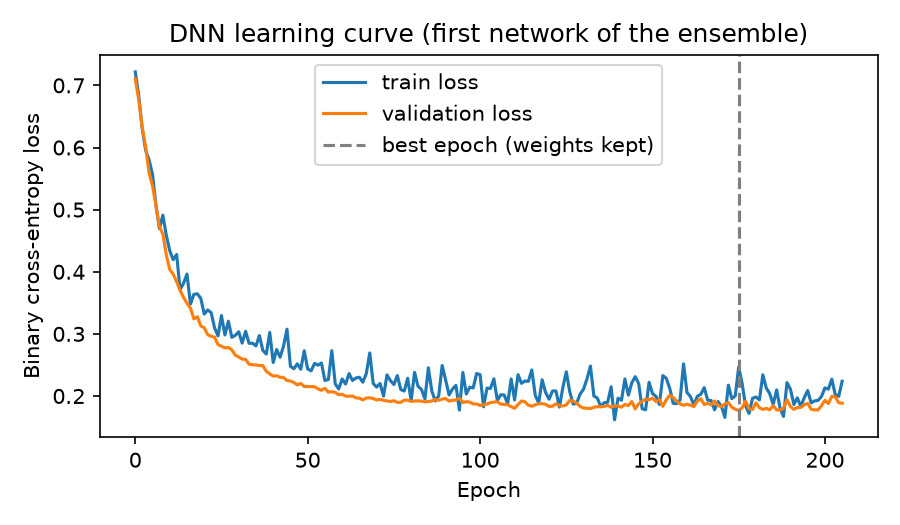

In [16]:
display(Image("results/figures/confusion.png", width=360), Image("results/figures/roc.png", width=420))
display(Image("results/figures/learning_curve.png", width=600))

**Is the DNN significantly better than the others?** McNemar's exact test looks only at students where exactly one of two models is right.
If the models were equally good, each such student would be a coin flip. A p-value above 0.05 means the difference could easily be chance.

In [17]:
display(pd.DataFrame(d["mcnemar_vs"]).T.rename(columns={"dnn_right_only": "only DNN right", "other_right_only": "only other right", "p_value": "p-value"}).round(3))

,only DNN right,only other right,p-value
Majority class,15.0,6.0,0.078
Naive rule (G2 < 10),6.0,4.0,0.754
Logistic regression,6.0,4.0,0.754
Random forest,9.0,2.0,0.065
XGBoost,5.0,3.0,0.727


**Interpretation.**
- The DNN has the highest test accuracy, 91.5%: 119 of 130 students correct, with 15 of 20 at-risk students caught and 6 false alarms.
- None of the differences from the rule, logistic regression or XGBoost is statistically significant (McNemar p ≈ 0.73–0.75).
- With 130 students, one student moves accuracy by 0.8 points, and the 95% interval spans 85.5–95.2%.
- The 5 retrained copies range from 91.5% to 93.1%.
- The honest claim: **the DNN performs as well as the best traditional models, at about 91–92% accuracy.** It does not clearly beat them.

**Learning curve.** Training and validation loss fall together and level off after about 100 epochs. There is no widening gap, so the network is not overfitting; heavy dropout (48%) and weight decay keep it in check.
Training loss is noisier and slightly higher because dropout is active while it is measured. Early stopping kept the best epoch (176).

**Decision threshold (analysis on training data only).** The model flags a student when P(at risk) ≥ 0.5.
The curve below uses out-of-fold predictions on the training students, so each student is predicted by a model that never saw them.
It shows the precision/recall trade-off: lowering the threshold to 0.3 would catch about 84% of at-risk students instead of 69%, at the cost of more false alarms.
That is a policy choice for a school. The deployed model keeps the default 0.5, and nothing is tuned on the test set.

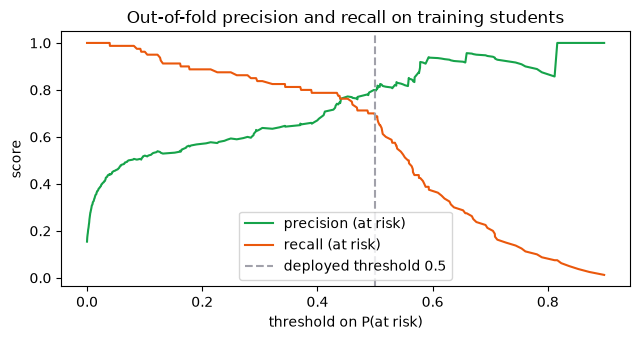

threshold 0.3: recall 0.838, precision 0.632, accuracy 0.900
threshold 0.4: recall 0.787, precision 0.677, accuracy 0.909
threshold 0.5: recall 0.688, precision 0.797, accuracy 0.925


In [18]:
oof = cross_val_predict(tune.build_dnn(params), train, train.at_risk, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                        method="predict_proba", n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(train.at_risk, oof)
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(thr, prec[:-1], color=GREEN, label="precision (at risk)"); ax.plot(thr, rec[:-1], color=ORANGE, label="recall (at risk)")
ax.axvline(0.5, color=GREY, ls="--", label="deployed threshold 0.5")
ax.set(xlabel="threshold on P(at risk)", ylabel="score", title="Out-of-fold precision and recall on training students"); ax.legend(); plt.tight_layout(); plt.show()
for t in [0.3, 0.4, 0.5]:
    yhat = (oof >= t).astype(int)
    print(f"threshold {t}: recall {yhat[train.at_risk == 1].mean():.3f}, precision {train.at_risk[yhat == 1].mean():.3f}, accuracy {(yhat == train.at_risk).mean():.3f}")

## 11. What the model relies on

**Permutation importance** shuffles one input column at a time in the test set and measures how much the DNN's ROC-AUC drops.
A large drop means the model depends on that column. This is analysis only; nothing is tuned on it.

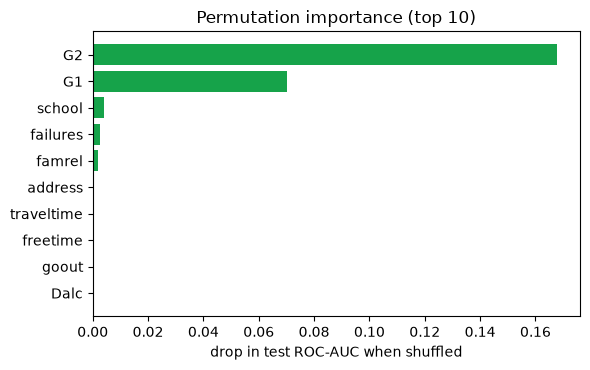

In [19]:
from sklearn.inspection import permutation_importance

dnn = joblib.load("models/dnn.joblib")
imp = permutation_importance(dnn, test[FEATURES], test.at_risk, scoring="roc_auc", n_repeats=20, random_state=SEED)
imp = pd.Series(imp.importances_mean, index=FEATURES).sort_values().tail(10)
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.barh(imp.index, imp.values, color=GREEN); ax.set(xlabel="drop in test ROC-AUC when shuffled", title="Permutation importance (top 10)")
plt.tight_layout(); plt.show()

## 12. Predicting individual students

This is what the Streamlit app (`streamlit run app.py`) does. One row of raw student data goes through the saved pipeline (encode → select → 5-network ensemble), and the app reads off the probability.

In [20]:
sample = pd.concat([test[test.at_risk == 1].head(3), test[test.at_risk == 0].head(3)])
out = sample[["G1", "G2", "failures", "absences", "studytime", "higher", "G3"]].copy()
out["P(at risk)"] = dnn.predict_proba(sample[FEATURES])[:, 1].round(3)
out["predicted"] = np.where(out["P(at risk)"] >= 0.5, "At risk", "Pass")
out["actual"] = np.where(sample.at_risk == 1, "At risk", "Pass")
out

,G1,G2,failures,absences,studytime,higher,G3,P(at risk),predicted,actual
256,7,8,1,26,1,no,8,0.658,At risk,At risk
168,7,8,0,0,2,yes,8,0.577,At risk,At risk
646,11,12,0,6,2,yes,9,0.007,Pass,At risk
21,11,12,0,0,1,yes,12,0.003,Pass,Pass
208,13,12,0,0,1,yes,12,0.002,Pass,Pass
278,9,12,0,2,1,yes,13,0.014,Pass,Pass


## 13. Under the hood: the network in NumPy

**13a. The saved network's forward pass, in NumPy.** A trained network is matrix multiplications plus simple element-wise functions.
This cell takes the first network of the saved ensemble and recomputes its predictions with NumPy only:
- `h @ W.T + b` for each linear layer;
- BatchNorm with the running mean and variance from training;
- ReLU as `max(0, h)`, and dropout does nothing at prediction time;
- finally the sigmoid.

The result must match PyTorch.

In [21]:
X = np.asarray(dnn[:-1].transform(test), dtype="float32")  # every pipeline step except the model: encode + select
first = dnn.named_steps["model"].models_[0].net

h = X
for layer in first:
    if isinstance(layer, torch.nn.Linear):          # h = h W^T + b
        h = h @ layer.weight.detach().numpy().T + layer.bias.detach().numpy()
    elif isinstance(layer, torch.nn.BatchNorm1d):   # normalise with running statistics, then scale (gamma) and shift (beta)
        h = (h - layer.running_mean.numpy()) / np.sqrt(layer.running_var.numpy() + layer.eps)
        h = h * layer.weight.detach().numpy() + layer.bias.detach().numpy()
    elif isinstance(layer, torch.nn.ReLU):
        h = np.maximum(h, 0)
p_numpy = 1 / (1 + np.exp(-h[:, 0]))

with torch.no_grad():
    p_torch = torch.sigmoid(first(torch.from_numpy(X))).numpy()[:, 0]
print("largest difference between NumPy and PyTorch:", np.abs(p_numpy - p_torch).max())
assert np.allclose(p_numpy, p_torch, atol=1e-5)

largest difference between NumPy and PyTorch: 1.1920929e-07


**13b. A network trained from scratch in NumPy** (course lab 6), from `src/numpy_mlp.py`. It uses the same 10 selected inputs, one hidden layer of 16 ReLU units and a sigmoid output.
The binary cross-entropy is minimised by mini-batch gradient descent, and every gradient is derived by hand with the chain rule:

- dL/dz₂ = (p − y) / n, because sigmoid and cross-entropy simplify
- dW₂ = a₁ᵀ · dz₂
- dz₁ = (dz₂ · W₂ᵀ) ⊙ 1[z₁ > 0]
- dW₁ = Xᵀ · dz₁

A **numerical gradient check** (course lab 2) compares each hand-derived gradient with (L(w + ε) − L(w − ε)) / 2ε.

gradient check: max relative error 2.00e-09 (below 1e-6 = correct)


NumPy network: 5-fold CV accuracy 0.929 ± 0.038; locked test accuracy 0.923, macro-F1 0.863


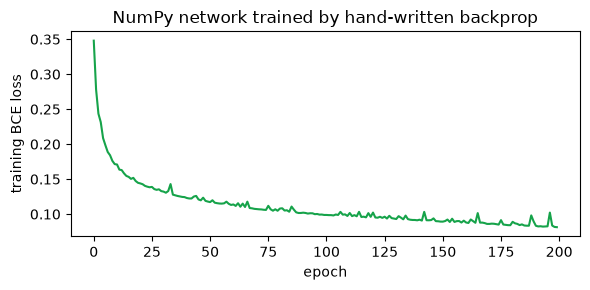

In [22]:
pre10 = Pipeline(make_preprocessor(params["k"])).fit(train, train.at_risk)   # same preprocessing, fitted on training rows
X_tr, X_te = (np.asarray(pre10.transform(d_), dtype=float) for d_ in (train, test))
y_tr, y_te = train.at_risk.to_numpy(float), test.at_risk.to_numpy()

print(f"gradient check: max relative error {gradient_check(NumpyMLP(params['k'], 16), X_tr[:64], y_tr[:64]):.2e} (below 1e-6 = correct)")

cv_acc = []  # 5-fold CV on the training students, preprocessing refitted inside each fold
for fit_idx, val_idx in StratifiedKFold(5, shuffle=True, random_state=SEED).split(train, train.at_risk):
    f, v = train.iloc[fit_idx], train.iloc[val_idx]
    p_ = Pipeline(make_preprocessor(params["k"])).fit(f, f.at_risk)
    m_ = NumpyMLP(params["k"], 16).fit(np.asarray(p_.transform(f), float), f.at_risk.to_numpy(float))
    cv_acc.append((m_.predict(np.asarray(p_.transform(v), float)) == v.at_risk.to_numpy()).mean())

scratch = NumpyMLP(params["k"], 16).fit(X_tr, y_tr)
pred = scratch.predict(X_te)
print(f"NumPy network: 5-fold CV accuracy {np.mean(cv_acc):.3f} ± {np.std(cv_acc):.3f}; "
      f"locked test accuracy {accuracy_score(y_te, pred):.3f}, macro-F1 {f1_score(y_te, pred, average='macro'):.3f}")
plt.figure(figsize=(6, 3)); plt.plot(scratch.history["train"], color=GREEN)
plt.xlabel("epoch"); plt.ylabel("training BCE loss"); plt.title("NumPy network trained by hand-written backprop"); plt.tight_layout(); plt.show()

## 14. The same network in Keras

The course covers TensorFlow/Keras as well as PyTorch, so the final architecture is rebuilt here with the same inputs and hyperparameters.
- **Sequential API**: a plain stack of layers.
- **Functional API**: the same graph written as explicit tensor-to-tensor calls. It is identical here, and it is the style needed for branching models.
- **Callbacks** replace the hand-written PyTorch loop:
  - `EarlyStopping(restore_best_weights=True)` does the same job as the patience logic;
  - `ModelCheckpoint` saves the best model to disk, which is then **reloaded** and checked.

This is a single network, so it is compared with a single PyTorch network rather than the 5-network ensemble.

parameters  Sequential: 417  Functional: 417  (includes non-trainable BatchNorm running statistics)


Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8)              │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 417 (1.63 KB)

 Trainable params: 369 (1.44 KB)

 Non-trainable params: 48 (192.00 B)

reloaded checkpoint predicts like a saved model: [0.002 0.002 0.007 0.001 0.003]


Keras (1 network):   stopped after 133 epochs; test accuracy 0.923, macro-F1 0.846
PyTorch (1 network): test accuracy 0.885, macro-F1 0.811


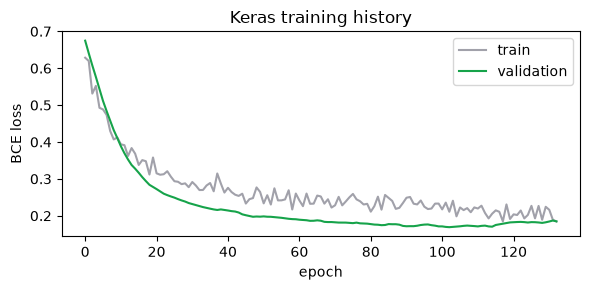

In [23]:
import keras
from keras import layers

def hidden_block(x, units):
    x = layers.Dense(units, kernel_initializer="he_normal")(x)
    if params["batchnorm"]:
        x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return layers.Dropout(params["dropout"])(x)

keras.utils.set_random_seed(SEED)
seq = keras.Sequential([keras.Input((params["k"],))])        # Sequential API
for units in hidden:
    seq.add(layers.Dense(units, kernel_initializer="he_normal"))
    if params["batchnorm"]:
        seq.add(layers.BatchNormalization())
    seq.add(layers.ReLU()); seq.add(layers.Dropout(params["dropout"]))
seq.add(layers.Dense(1, activation="sigmoid"))

inputs = keras.Input((params["k"],))                           # Functional API: same network
x = inputs
for units in hidden:
    x = hidden_block(x, units)
functional = keras.Model(inputs, layers.Dense(1, activation="sigmoid")(x))
print("parameters  Sequential:", seq.count_params(), " Functional:", functional.count_params(), " (includes non-trainable BatchNorm running statistics)")
functional.summary()

functional.compile(optimizer=keras.optimizers.AdamW(learning_rate=params["lr"], weight_decay=params["weight_decay"]),
                   loss="binary_crossentropy", metrics=["accuracy"])
callbacks = [keras.callbacks.EarlyStopping(patience=30, restore_best_weights=True),
             keras.callbacks.ModelCheckpoint("models/keras_best.keras", save_best_only=True)]
history = functional.fit(X_tr.astype("float32"), y_tr.astype("float32"), validation_split=0.15, epochs=400,
                         batch_size=params["batch_size"], callbacks=callbacks, verbose=0)

reloaded = keras.models.load_model("models/keras_best.keras")  # model saving/loading
print("reloaded checkpoint predicts like a saved model:", reloaded.predict(X_te[:5].astype("float32"), verbose=0)[:, 0].round(3))
k_pred = (functional.predict(X_te.astype("float32"), verbose=0)[:, 0] >= 0.5).astype(int)
t_pred = tune.build_dnn(params, n_models=1).fit(train, train.at_risk).predict(test)
print(f"Keras (1 network):   stopped after {len(history.history['loss'])} epochs; test accuracy {accuracy_score(y_te, k_pred):.3f}, macro-F1 {f1_score(y_te, k_pred, average='macro'):.3f}")
print(f"PyTorch (1 network): test accuracy {accuracy_score(y_te, t_pred):.3f}, macro-F1 {f1_score(y_te, t_pred, average='macro'):.3f}")

plt.figure(figsize=(6, 3)); plt.plot(history.history["loss"], color=GREY, label="train"); plt.plot(history.history["val_loss"], color=GREEN, label="validation")
plt.xlabel("epoch"); plt.ylabel("BCE loss"); plt.title("Keras training history"); plt.legend(); plt.tight_layout(); plt.show()

## 15. Training experiments from the course practicals

These runs answer "why this choice?" with evidence, using **training data only**.

**Setup.**
- Every run trains one copy of the final architecture on the same 85/15 split of the 519 training students.
- Each run lasts 100 epochs with no early stopping, so the curves are comparable.
- Batches come from a PyTorch `Dataset`/`DataLoader` (`src/experiments.py`).
- None of these runs touches the test set or changes the final model.

**Caveat:** the validation slice is only 78 students, so one student is 1.3 accuracy points. Read these as trends, not rankings.

In [24]:
data = experiments.prepare(train, k=params["k"])
def show(results, title):
    fig, ax = plt.subplots(figsize=(7, 3.5))
    for name, h in results.items():
        ax.plot(h["val"], label=name)
    ax.set(xlabel="epoch", ylabel="validation BCE loss", title=title); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
    display(pd.DataFrame(experiments.summary(results)).set_index("run").round(3))

**15a. Optimisers** (lab 11): plain SGD, SGD with momentum 0.9, RMSprop, Adam and AdamW. SGD runs use lr 0.01 and the adaptive methods lr 0.001, which are the usual starting points for each.

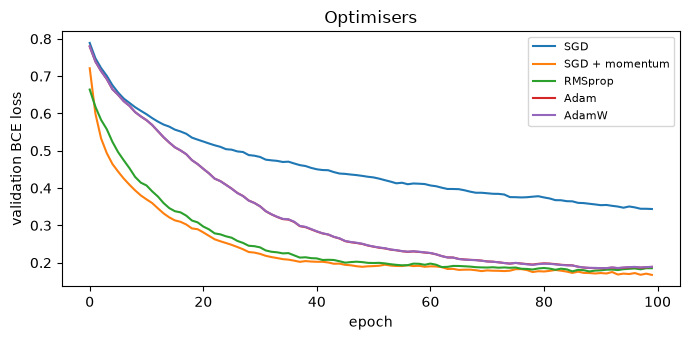

,best_val_loss,best_epoch,val_acc_at_best,final_val_loss,seconds
run,,,,,
SGD,0.344,100,0.872,0.344,0.252
SGD + momentum,0.167,100,0.910,0.167,0.262
RMSprop,0.177,89,0.923,0.185,0.311
Adam,0.185,91,0.923,0.189,0.344
AdamW,0.185,91,0.923,0.189,0.354


In [25]:
opt_runs = {o: experiments.run(data, optimizer=o, lr=0.01 if "SGD" in o else 1e-3) for o in ["SGD", "SGD + momentum", "RMSprop", "Adam", "AdamW"]}
show(opt_runs, "Optimisers")

**15b. Learning-rate schedules** (lab 11): a constant rate, step decay (halve every 30 epochs) and exponential decay (×0.97 per epoch), all with AdamW starting at lr 0.001.

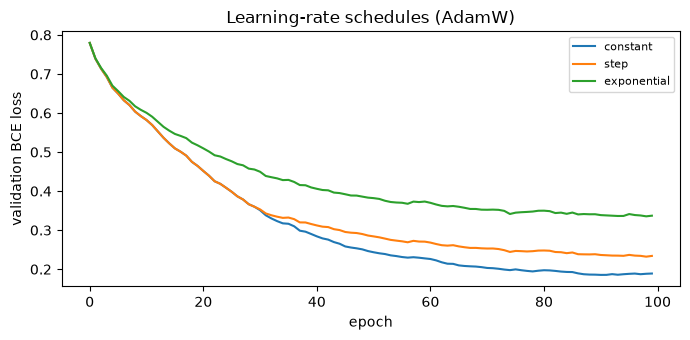

,best_val_loss,best_epoch,val_acc_at_best,final_val_loss,seconds
run,,,,,
constant,0.185,91,0.923,0.189,0.354
step,0.232,99,0.910,0.234,0.345
exponential,0.335,99,0.923,0.337,0.345


In [26]:
sched_runs = {"constant": opt_runs["AdamW"]} | {s: experiments.run(data, schedule=s) for s in ["step", "exponential"]}
show(sched_runs, "Learning-rate schedules (AdamW)")

**15c. Batch, stochastic and mini-batch gradient descent** (lab 7): plain SGD at lr 0.05 with batches of 441 (the whole split), 1 and 32 rows.
BatchNorm is switched off here, because it cannot compute batch statistics on a single row.

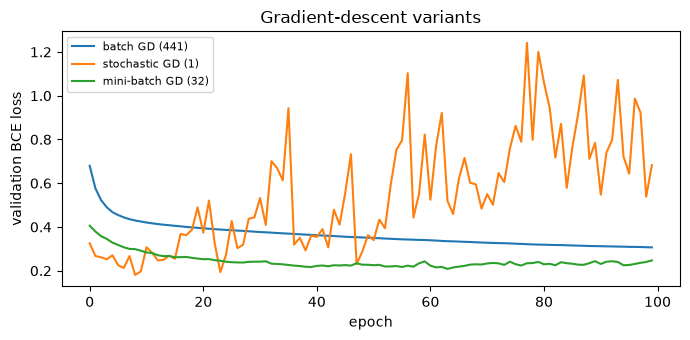

,best_val_loss,best_epoch,val_acc_at_best,final_val_loss,seconds
run,,,,,
batch GD (441),0.307,100,0.833,0.307,0.124
stochastic GD (1),0.181,9,0.897,0.683,7.139
mini-batch GD (32),0.208,64,0.897,0.247,0.356


In [27]:
gd_runs = {"batch GD (441)": experiments.run(data, optimizer="SGD", lr=0.05, batch_size=len(data[0]), batchnorm=False),
           "stochastic GD (1)": experiments.run(data, optimizer="SGD", lr=0.05, batch_size=1, batchnorm=False),
           "mini-batch GD (32)": experiments.run(data, optimizer="SGD", lr=0.05, batch_size=32, batchnorm=False)}
show(gd_runs, "Gradient-descent variants")

**15d. Weight initialisation** (lab 8): He (used), Xavier/Glorot, and all-zeros. All-zeros is a pitfall: every unit in a layer starts identical, so they all receive the same gradient and never become different.

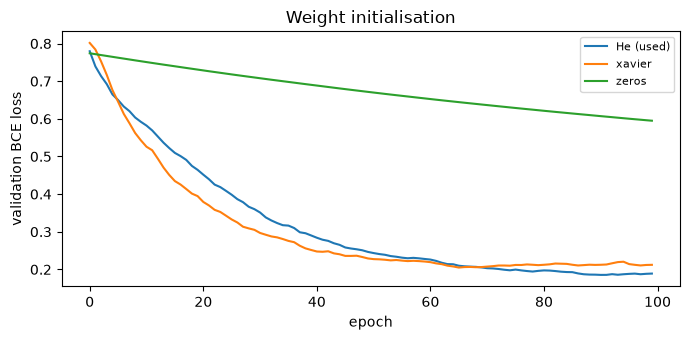

,best_val_loss,best_epoch,val_acc_at_best,final_val_loss,seconds
run,,,,,
He (used),0.185,91,0.923,0.189,0.354
xavier,0.205,66,0.897,0.212,0.350
zeros,0.595,100,0.846,0.595,0.339


In [28]:
init_runs = {"He (used)": opt_runs["AdamW"]} | {i: experiments.run(data, init=i) for i in ["xavier", "zeros"]}
show(init_runs, "Weight initialisation")

**15e. Activation functions** (lab 5): ReLU (used), tanh and sigmoid in the hidden layers.

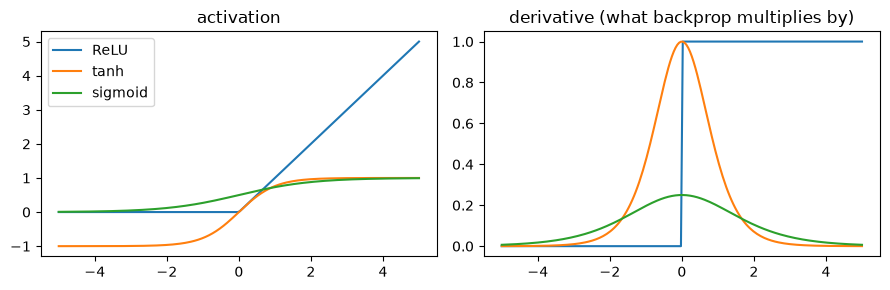

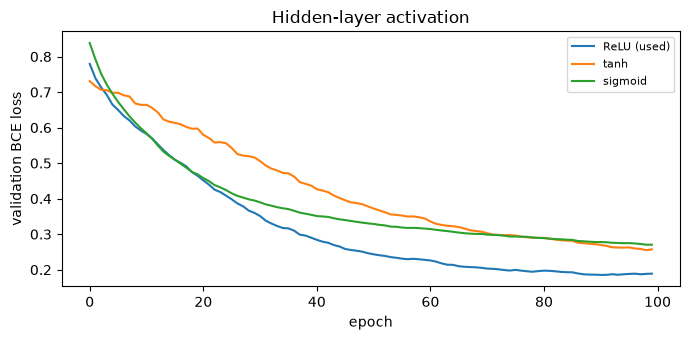

,best_val_loss,best_epoch,val_acc_at_best,final_val_loss,seconds
run,,,,,
ReLU (used),0.185,91,0.923,0.189,0.354
tanh,0.255,99,0.859,0.257,0.365
sigmoid,0.270,99,0.859,0.270,0.351


In [29]:
z = np.linspace(-5, 5, 200); sig = 1 / (1 + np.exp(-z))
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for f_, d_, name in [(np.maximum(z, 0), (z > 0).astype(float), "ReLU"), (np.tanh(z), 1 - np.tanh(z) ** 2, "tanh"), (sig, sig * (1 - sig), "sigmoid")]:
    axes[0].plot(z, f_, label=name); axes[1].plot(z, d_, label=name)
axes[0].set_title("activation"); axes[1].set_title("derivative (what backprop multiplies by)"); axes[0].legend(); plt.tight_layout(); plt.show()

act_runs = {"ReLU (used)": opt_runs["AdamW"]} | {a: experiments.run(data, activation=a) for a in ["tanh", "sigmoid"]}
show(act_runs, "Hidden-layer activation")

**What the experiments show** (validation loss after 100 epochs on 78 validation students; small differences are noise):
- **Optimisers.** Plain SGD learns slowest (best validation loss 0.344). Adding momentum 0.9 fixes that (0.167). RMSprop, Adam and AdamW get to about 0.18 with no tuning of the learning rate. AdamW is used because its weight decay is applied correctly.
- **Learning-rate schedules.** With a starting rate of 0.001, step and exponential decay only slow learning down (0.232 and 0.335 vs 0.185 constant). A schedule pays off when the starting rate is high; here, early stopping already ends training at the right time.
- **Batch, stochastic and mini-batch gradient descent.**
  - Batch GD takes one step per epoch, so it is smooth but slow (0.307 after 100 epochs).
  - Stochastic GD reaches the lowest loss at epoch 9, then overfits and becomes noisy (0.683 at the end), and it is 20× slower per epoch.
  - Mini-batches are the practical middle ground.
- **Initialisation.** He (0.185) and Xavier (0.205) both work. All-zeros stays stuck at the majority-class answer (84.6%), because every unit in a layer starts identical, gets the same gradient and never becomes different (the symmetry problem).
- **Activations.** ReLU (0.185) beats tanh (0.255) and sigmoid (0.270). Their derivatives are small away from zero (the sigmoid's is at most 0.25), so gradients shrink layer by layer.

## 16. Hardware: CPU vs GPU

The same network is trained for 50 epochs on every available device: the CPU, plus `cuda` (NVIDIA, on Kaggle) or `mps` (Apple) if present.
The network has only a few hundred weights and each batch holds 32 rows, so the cost of launching GPU work can outweigh the maths it saves.

In [30]:
X_bench, y_bench = torch.randn(519, 10), (torch.rand(519) < 0.15).float()

def bench(device, epochs=50):
    torch.manual_seed(0)
    model = MLP(10, hidden, params["dropout"], params["batchnorm"]).to(device)
    opt, loss_fn = torch.optim.AdamW(model.parameters(), lr=1e-3), torch.nn.BCEWithLogitsLoss()
    Xd, yd = X_bench.to(device), y_bench.to(device)
    start = time.perf_counter()
    for _ in range(epochs):
        for i in range(0, len(Xd) - 1, 32):
            opt.zero_grad(); loss_fn(model(Xd[i:i + 32]), yd[i:i + 32]).backward(); opt.step()
    if device == "cuda": torch.cuda.synchronize()
    if device == "mps": torch.mps.synchronize()
    return time.perf_counter() - start

for dev in ["cpu"] + ["cuda"] * torch.cuda.is_available() + ["mps"] * torch.backends.mps.is_available():
    bench(dev, epochs=2)  # warm-up: the first GPU call pays a one-off start-up cost
    print(f"{dev:5s} {bench(dev):.2f} s for 50 epochs" + (f"  ({torch.cuda.get_device_name()})" if dev == "cuda" else ""))

cpu   0.25 s for 50 epochs


mps   0.74 s for 50 epochs


## 17. Supplementary: no grades, and results history

**Ablation without G1 and G2.** An earlier version of the project also trained an "early-warning" model with no grades at all.
It is kept as supplementary research (git tag `v1-two-scenarios`, frozen results in `results/supplementary/`).
It answers the question "is the model just copying G2?": without grades, no model beats predicting "pass" for everyone (84.6% accuracy).

In [31]:
early = json.load(open("results/supplementary/early_warning_metrics.json"))
cols = {"cv_balanced_acc": "CV balanced acc", "cv_recall_at_risk": "CV recall", "cv_f1_macro": "CV macro-F1",
        "test_accuracy": "test accuracy", "test_f1_macro": "test macro-F1", "test_roc_auc": "test ROC-AUC"}
pd.DataFrame(early["models"]).T[list(cols)].rename(columns=cols).astype(float).round(3)

,CV balanced acc,CV recall,CV macro-F1,test accuracy,test macro-F1,test ROC-AUC
Majority class,0.500,0.000,0.458,0.846,0.458,0.500
Logistic regression,0.721,0.596,0.685,0.785,0.642,0.791
Random forest,0.718,0.521,0.721,0.838,0.653,0.790
XGBoost,0.727,0.567,0.711,0.808,0.652,0.743
DNN (MLP),0.744,0.671,0.687,0.762,0.622,0.797


**Results history of the primary model.** The locked test set was scored once per version. Every change was motivated by cross-validation evidence or a methodological audit, never by the test score.

| Version | Change (reason) | CV accuracy | Test accuracy | 5 seeds (test) |
|---|---|---|---|---|
| v1.0 | One network, k-NN mutual information | – | 0.908 | – |
| v1.1 | 5-network ensemble (a single network's CV macro-F1 varied 0.072 between folds, against about 0.045 for the other models) | 0.919 | 0.900 | 0.912 ± 0.004 |
| **v2 (final)** | Discrete mutual information (all inputs are discrete; v1 selection unstable across folds), Optuna re-run with 5×2 CV | **0.925** | **0.915** | **0.923 ± 0.008** |

## 18. Conclusions and limitations

**Conclusions.**
- **Result.** The final DNN (10 → 16 → 8 → 1, 369 weights per network, an average of 5 networks) scores **91.5% accuracy on the locked test set** (95% CI 85.5–95.2%).
  - Over 5 retrained seeds: **92.3 ± 0.8%**.
  - Cross-validation: **92.5%**, ROC-AUC 0.97.
  - Test precision for at-risk students: 71%; recall: 75%.
- **Comparison.** Logistic regression, XGBoost and even the rule "G2 < 10" reach about 90% on test and 90–93% in CV.
  - McNemar's tests find no significant difference between the DNN and the strong baselines.
  - A one-hidden-layer NumPy network and a single Keras network reach a similar level (section 13 and section 14).
  - With the period grades available, this problem is close to linearly separable, and about 92% is the realistic ceiling.
- **Feature selection.** The model needs only 10 of the 45 encoded columns, led by G1, G2 and past failures.
- **CHO practicals.** NumPy backprop with a gradient check, Keras Sequential and Functional APIs with callbacks and reloading, PyTorch `DataLoader`, and comparisons of optimisers, schedules, initialisation, activations and gradient-descent variants (sections 13–15).
- **Hardware.** The network is tiny, so a GPU brings no speed-up (section 16).

**Limitations.**
- **Small data.** 649 students from two schools in 2005–06, and a test set of 130 (20 at risk): one student moves accuracy by 0.8 points. Single networks vary between about 88.5% and 93% on test depending on their random start.
- **Test set seen more than once.** It was scored once per version (3 times in total). The CV estimate (92.5%) agrees with the test score, which suggests little optimism, but it cannot be ruled out entirely.
- **Recall.** At the default 0.5 threshold, about 1 in 4 at-risk students is missed (section 10 shows the threshold trade-off).
- **Responsible use.** The inputs include sensitive attributes such as sex, family situation and address. The model should start a conversation with a student, not make a decision about them.

Every decision, the alternatives considered and the evidence are in `DECISIONS.md`. Full result tables are in `results/RESULTS.md`.